# TP2 — Etapa 2: Evaluación de Similitud, Entrenamiento y Comparación de Modelos

Notebook integral de evaluación y entrenamiento (ver `ENUNCIADO.md`, secciones 4.3, 5 y 6.3):
1. Evaluación de la **Etapa 1** (`NDCG@10`, `precision@10`, `accuracy`, `cosine` vs `l2`, `TOP_K` y calibración de `SIMILARITY_THRESHOLD` sobre `valid`).
2. Entrenamiento y evaluación del **Modelo A** (`ResNet18` fine-tuned, comparando 2 estrategias).
3. Entrenamiento y evaluación del **Modelo B** (`CNNCustom` residual, con tabla de experimentos vs `CNNCustomSimple`).
4. Evaluación sobre conjunto independiente, comparación de embeddings en Etapa 1 + **PCA / t-SNE**, análisis de errores (FP/FN), costo computacional en CPU y comparativa **`yolov8n.pt` vs `yolo26n.pt`**.

> Entorno recomendado en Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

**Notebook en Google Colab:** https://colab.research.google.com/drive/1KAS_HEGNcmLv6qTblF_WUKPK6kCrfoJB?usp=sharing

## Equipo
- **Emanuel Speranza** — `@Manuspe`

## 1. Clonar el repositorio y Drive opcional

In [1]:
import os
from pathlib import Path

REPO_URL = "https://github.com/Manuspe/tuia-dog-recognition-app.git"
BRANCH = "feature/tp2-razas-perros"

if (Path.cwd() / "src" / "lib").is_dir():
    ROOT = Path.cwd()
elif Path("/content/proyecto/src/lib").is_dir():
    ROOT = Path("/content/proyecto")
    %cd /content/proyecto
else:
    !git clone -b $BRANCH $REPO_URL /content/proyecto
    ROOT = Path("/content/proyecto")
    %cd /content/proyecto

USE_DRIVE = True
DRIVE_DIR = Path("/content/drive/MyDrive/TP2_Perros")
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    import shutil
    if (DRIVE_DIR / "splits.csv").is_file():
        shutil.copy2(DRIVE_DIR / "splits.csv", ROOT / "data" / "splits.csv")

print("ROOT:", ROOT)

Cloning into '/content/proyecto'...
remote: Enumerating objects: 168, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 168 (delta 47), reused 38 (delta 38), pack-reused 97 (from 1)
Receiving objects: 100% (168/168), 1020.60 KiB | 15.95 MiB/s, done.
Resolving deltas: 100% (86/86), done.
/content/proyecto
Mounted at /content/drive
ROOT: /content/proyecto


In [2]:
!unzip -q -o /content/drive/MyDrive/TP2_Perros/independent_dataset.zip -d /content/proyecto/data/dataset/

## 2. Instalar dependencias

In [3]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations==2.0.8 onnxruntime "ultralytics>=8.4.0" seaborn

## 3. Configuración del entorno

In [4]:
import json
import logging
import random
import sys
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

logging.basicConfig(level=logging.INFO, format="%(levelname)s:%(name)s:%(message)s")

os.environ["USE_PGVECTOR"] = "false"
os.environ["BASELINE_MODEL_NAME"] = "resnet18"
os.environ["EMBEDDING_DIM"] = "512"
os.environ["IMAGE_SIZE"] = "224"
os.environ["MODEL_PATH"] = str(ROOT / "models")
os.environ["TORCH_HOME"] = str(ROOT / "models" / "torch")
os.environ["DATA_PATH"] = str(ROOT / "data")
os.environ["DATASET_PATH"] = str(ROOT / "data" / "dataset")
os.environ["SPLITS_PATH"] = str(ROOT / "data" / "splits.csv")
os.environ["OUTPUT_PATH"] = str(ROOT / "output")
os.environ["TRAIN_EPOCHS"] = "35"
os.environ["EARLY_STOPPING_PATIENCE"] = "10"
os.environ["BATCH_SIZE"] = "32"

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

random.seed(settings.random_seed)
np.random.seed(settings.random_seed)
torch.manual_seed(settings.random_seed)

print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: /content/proyecto/data/dataset
GPU disponible: True


## 4. Descarga del dataset y carga de splits

In [5]:
!python scripts/download_dataset.py

double_space_dir = settings.dataset_path / "valid" / "American  Spaniel"
clean_dir = settings.dataset_path / "valid" / "American Spaniel"
if double_space_dir.is_dir() and not clean_dir.exists():
    double_space_dir.rename(clean_dir)

from lib.splits import IMAGE_SUFFIXES, load_splits, normalize_breed_name

splits, classes = load_splits(settings.dataset_path, settings.splits_path)
print({k: len(v) for k, v in splits.items()}, "| clases:", len(classes))

indep_root = settings.dataset_path / "independent"
indep_samples = []
class_to_idx = {c: i for i, c in enumerate(classes)}
if indep_root.is_dir():
    for bd in sorted(p for p in indep_root.iterdir() if p.is_dir()):
        bname = normalize_breed_name(bd.name)
        if bname in class_to_idx:
            for f in sorted(bd.iterdir()):
                if f.is_file() and f.suffix.lower() in IMAGE_SUFFIXES:
                    indep_samples.append((f, class_to_idx[bname]))
print("Muestras en conjunto independiente (raza unica):", len(indep_samples))

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Dataset disponible en /content/proyecto/data/dataset
{'train': 7729, 'valid': 687, 'test': 696} | clases: 70
Muestras en conjunto independiente (raza unica): 125


## 5. Etapa 1 — Evaluación de búsqueda por similitud (Baseline `ResNet18` 512-d)

- Galería: `train` (nunca se indexan `valid`, `test` ni `independent`).
- Métrica `NDCG@10` calculada con `lib.evaluation.metrics.ndcg_at_k(relevances, k=10, n_relevant=conteo_en_galeria)`.
- Se comparan `cosine` y `l2`, el efecto de `TOP_K` y se calibra `SIMILARITY_THRESHOLD` conjuntamente sobre **`valid`** (consultas positivas de perros) y **`independent_no_dogs`** (consultas negativas fuera de dominio), eligiendo el umbral más alto que conserva la accuracy de validación y maximiza el rechazo (`"unknown"`) de imágenes sin perros.

In [6]:
from collections import Counter
from tqdm.auto import tqdm
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))

def extract_matrix(samples, extractor_fn, desc="Extrayendo"):
    vecs, breeds, paths = [], [], []
    for path, idx in tqdm(samples, desc=desc):
        bgr = cv2.imread(str(path))
        vecs.append(extractor_fn(bgr))
        breeds.append(classes[idx])
        paths.append(path)
    return np.asarray(vecs, dtype=np.float32), breeds, paths

def eval_retrieval(gal_vecs, gal_breeds, q_vecs, q_breeds, metric="cosine", top_k=10, threshold=0.55):
    gal_counts = Counter(gal_breeds)
    gal_b = np.asarray(gal_breeds)
    similarity.similarity_metric = metric
    similarity.similarity_threshold = threshold

    if metric == "cosine":
        sim_mat = q_vecs @ gal_vecs.T
    else:
        dists = np.linalg.norm(q_vecs[:, None, :] - gal_vecs[None, :, :], axis=2)
        sim_mat = 1.0 / (1.0 + dists)

    ndcgs, p_at_k, preds = [], [], []
    for i in range(len(q_vecs)):
        scores = sim_mat[i]
        top_idx = np.argsort(scores)[::-1][:top_k]
        rel = [1.0 if gal_b[j] == q_breeds[i] else 0.0 for j in top_idx]
        ndcgs.append(ndcg_at_k(rel, k=top_k, n_relevant=gal_counts[q_breeds[i]]))
        p_at_k.append(float(np.mean(rel)))
        neighbors = [Neighbor(path="", breed=str(gal_b[j]), score=float(scores[j])) for j in top_idx]
        pred_breed, _ = similarity.predict_breed_from_neighbors(neighbors)
        preds.append(pred_breed)

    acc = float(np.mean([p == t for p, t in zip(preds, q_breeds)]))
    unknown_rate = float(np.mean([p == "unknown" for p in preds]))
    return {
        "ndcg": float(np.mean(ndcgs)),
        "precision_at_k": float(np.mean(p_at_k)),
        "accuracy": acc,
        "unknown_rate": unknown_rate,
        "ndcg_list": ndcgs,
        "preds": preds,
        "sim_mat": sim_mat,
    }

gal_vecs_base, gal_breeds, gal_paths = extract_matrix(splits["train"], similarity.extract_embedding, "Galeria train")
val_vecs_base, val_breeds, val_paths = extract_matrix(splits["valid"], similarity.extract_embedding, "Consultas valid")
test_vecs_base, test_breeds, test_paths = extract_matrix(splits["test"], similarity.extract_embedding, "Consultas test")

Galeria train:   0%|          | 0/7729 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/proyecto/models/torch/hub/checkpoints/resnet18-f37072fd.pth



  0%|          | 0.00/44.7M [00:00<?, ?B/s]
 24%|██▍       | 10.8M/44.7M [00:00<00:00, 113MB/s]
100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


Consultas valid:   0%|          | 0/687 [00:00<?, ?it/s]

Consultas test:   0%|          | 0/696 [00:00<?, ?it/s]

In [7]:
# 1. Calibracion de SIMILARITY_THRESHOLD sobre valid + independent_no_dogs (negativos OOD)
nodogs_dir = settings.dataset_path / "independent_no_dogs"
nodogs_paths = (
    sorted([p for p in nodogs_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES])
    if nodogs_dir.is_dir()
    else []
)
nodogs_vecs_base = None
if nodogs_paths:
    nodogs_vecs_base = np.asarray(
        [similarity.extract_embedding(cv2.imread(str(p))) for p in tqdm(nodogs_paths, desc="Consultas no_dogs")],
        dtype=np.float32,
    )

def calibrate_threshold(gal_vecs, gal_breeds, val_vecs, val_breeds, nodogs_vecs=None):
    thresholds = np.round(np.linspace(0.30, 0.85, 12), 2)
    rows = []
    for th in thresholds:
        res_v = eval_retrieval(gal_vecs, gal_breeds, val_vecs, val_breeds, metric="cosine", top_k=10, threshold=float(th))
        nodogs_unk = np.nan
        if nodogs_vecs is not None and len(nodogs_vecs) > 0:
            sim_nd = nodogs_vecs @ gal_vecs.T
            unk_count = 0
            similarity.similarity_metric = "cosine"
            similarity.similarity_threshold = float(th)
            for i in range(len(nodogs_vecs)):
                top_idx = np.argsort(sim_nd[i])[::-1][:10]
                nbrs = [Neighbor(path="", breed=str(gal_breeds[j]), score=float(sim_nd[i, j])) for j in top_idx]
                pred_b, _ = similarity.predict_breed_from_neighbors(nbrs)
                if pred_b == "unknown":
                    unk_count += 1
            nodogs_unk = unk_count / len(nodogs_vecs)
        rows.append({
            "threshold": float(th),
            "val_accuracy": res_v["accuracy"],
            "val_unknown_rate": res_v["unknown_rate"],
            "nodogs_unknown_rate": nodogs_unk,
        })
    df_cal = pd.DataFrame(rows)
    max_val_acc = float(df_cal["val_accuracy"].max())
    eligible = df_cal[df_cal["val_accuracy"] >= max_val_acc - 0.005]
    if nodogs_vecs is not None and len(nodogs_vecs) > 0:
        best_row = eligible.sort_values(["nodogs_unknown_rate", "val_accuracy", "threshold"], ascending=[False, False, False]).iloc[0]
    else:
        best_row = eligible.sort_values(["val_accuracy", "threshold"], ascending=[False, False]).iloc[0]
    return float(best_row["threshold"]), df_cal

best_th, df_cal = calibrate_threshold(gal_vecs_base, gal_breeds, val_vecs_base, val_breeds, nodogs_vecs_base)
print(f"Umbral calibrado baseline (valid + no_dogs): {best_th:.2f}")
display(df_cal.round(4))

# 2. Comparacion cosine vs l2 y efecto de TOP_K en test
comp_rows = []
for metric in ("cosine", "l2"):
    for k in (1, 5, 10, 20):
        r = eval_retrieval(gal_vecs_base, gal_breeds, test_vecs_base, test_breeds, metric=metric, top_k=k, threshold=best_th)
        comp_rows.append({"metric": metric, "top_k": k, "ndcg@k": r["ndcg"], "precision@k": r["precision_at_k"], "accuracy": r["accuracy"]})
display(pd.DataFrame(comp_rows).round(4))

res_test_base = eval_retrieval(gal_vecs_base, gal_breeds, test_vecs_base, test_breeds, metric="cosine", top_k=10, threshold=best_th)
print(f"Test (cosine, K=10): NDCG@10={res_test_base['ndcg']:.4f}, P@10={res_test_base['precision_at_k']:.4f}, Acc={res_test_base['accuracy']:.4f}")

if indep_samples:
    ind_vecs_base, ind_breeds, ind_paths = extract_matrix(indep_samples, similarity.extract_embedding, "Consultas indep")
    res_ind_base = eval_retrieval(gal_vecs_base, gal_breeds, ind_vecs_base, ind_breeds, metric="cosine", top_k=10, threshold=best_th)
    res_ind_base_l2 = eval_retrieval(gal_vecs_base, gal_breeds, ind_vecs_base, ind_breeds, metric="l2", top_k=10, threshold=best_th)
    print(f"Independiente (cosine, K=10): NDCG@10={res_ind_base['ndcg']:.4f}, P@10={res_ind_base['precision_at_k']:.4f}, Acc={res_ind_base['accuracy']:.4f}")
    print(f"Independiente (l2, K=10):     NDCG@10={res_ind_base_l2['ndcg']:.4f}, P@10={res_ind_base_l2['precision_at_k']:.4f}, Acc={res_ind_base_l2['accuracy']:.4f}")

Consultas no_dogs:   0%|          | 0/15 [00:00<?, ?it/s]

Umbral calibrado baseline (valid + no_dogs): 0.80


,threshold,val_accuracy,val_unknown_rate,nodogs_unknown_rate
0,0.30,0.9360,0.0000,0.0000
1,0.35,0.9360,0.0000,0.0000
2,0.40,0.9360,0.0000,0.0000
3,0.45,0.9360,0.0000,0.0000
4,0.50,0.9360,0.0000,0.0000
5,0.55,0.9360,0.0000,0.0000
6,0.60,0.9360,0.0000,0.0000
7,0.65,0.9360,0.0000,0.1333
8,0.70,0.9360,0.0000,0.6000
9,0.75,0.9360,0.0000,0.8000


,metric,top_k,ndcg@k,precision@k,accuracy
0,cosine,1,0.9296,0.9296,0.9282
1,cosine,5,0.8949,0.8856,0.9397
2,cosine,10,0.8739,0.8603,0.9310
3,cosine,20,0.8456,0.8269,0.9296
4,l2,1,0.9296,0.9296,0.0747
5,l2,5,0.8949,0.8856,0.0747
6,l2,10,0.8739,0.8603,0.0747
7,l2,20,0.8456,0.8269,0.0747


Test (cosine, K=10): NDCG@10=0.8739, P@10=0.8603, Acc=0.9310


Consultas indep:   0%|          | 0/125 [00:00<?, ?it/s]

Independiente (cosine, K=10): NDCG@10=0.6953, P@10=0.6904, Acc=0.7440
Independiente (l2, K=10):     NDCG@10=0.6953, P@10=0.6904, Acc=0.0000


Top 10 peores razas (NDCG@10):


,ndcg
breed,
Bulldog,0.334072
Malinois,0.552836
Labradoodle,0.631171
Cockapoo,0.634406
Boston Terrier,0.653833
Bull Mastiff,0.672721
Rhodesian,0.673413
American Hairless,0.685181
American Spaniel,0.690962


Top 10 mejores razas (NDCG@10):


,ndcg
breed,
Dalmation,0.984824
Bichon Frise,0.985798
Clumber,0.990521
Saint Bernard,0.993057
Great Perenees,1.000000
Komondor,1.000000
Afghan,1.000000
Coyote,1.000000
Bermaise,1.000000


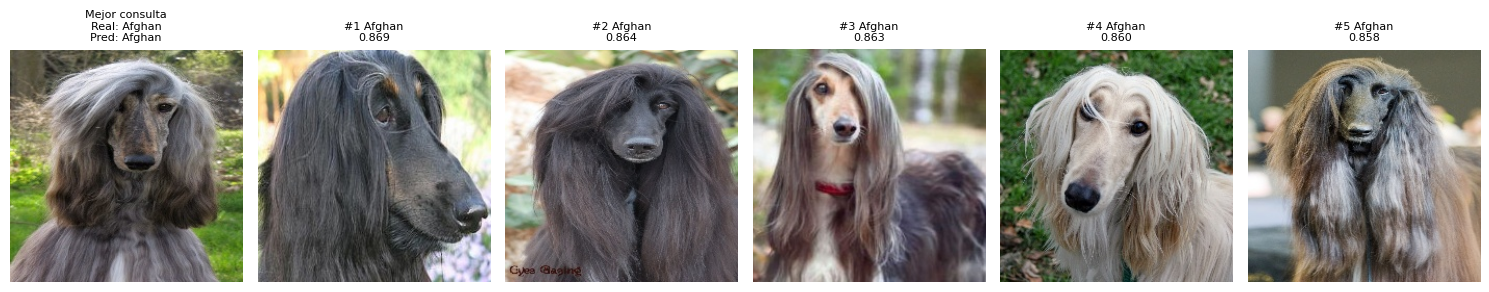

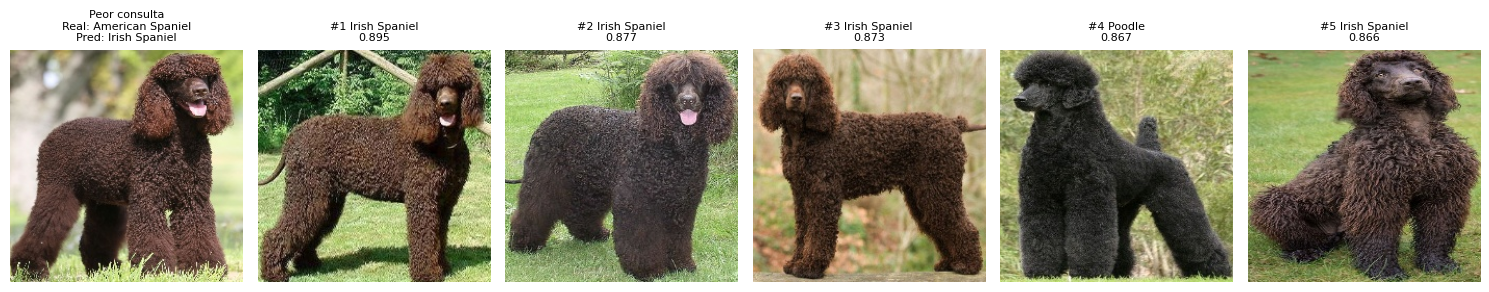

In [8]:
# Distribucion NDCG@10 por raza y ejemplos visuales Top-10
df_ndcg = pd.DataFrame({"breed": test_breeds, "ndcg": res_test_base["ndcg_list"]})
breed_ndcg = df_ndcg.groupby("breed")["ndcg"].mean().sort_values()
print("Top 10 peores razas (NDCG@10):")
display(breed_ndcg.head(10).to_frame())
print("Top 10 mejores razas (NDCG@10):")
display(breed_ndcg.tail(10).to_frame())

worst_idx = int(np.argmin(res_test_base["ndcg_list"]))
best_idx = int(np.argmax(res_test_base["ndcg_list"]))
for label, q_i in [("Mejor consulta", best_idx), ("Peor consulta", worst_idx)]:
    top5 = np.argsort(res_test_base["sim_mat"][q_i])[::-1][:5]
    fig, axes = plt.subplots(1, 6, figsize=(15, 3))
    q_bgr = cv2.imread(str(test_paths[q_i]))
    axes[0].imshow(cv2.cvtColor(q_bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"{label}\nReal: {test_breeds[q_i]}\nPred: {res_test_base['preds'][q_i]}", fontsize=8)
    axes[0].axis("off")
    for j_ax, g_idx in enumerate(top5, start=1):
        g_bgr = cv2.imread(str(gal_paths[g_idx]))
        axes[j_ax].imshow(cv2.cvtColor(g_bgr, cv2.COLOR_BGR2RGB))
        axes[j_ax].set_title(f"#{j_ax} {gal_breeds[g_idx]}\n{res_test_base['sim_mat'][q_i, g_idx]:.3f}", fontsize=8)
        axes[j_ax].axis("off")
    plt.tight_layout()
    plt.show()

## 6. Modelo A (obligatorio): Fine-tuning de `ResNet18`

Comparamos dos estrategias usando `ClassifierService`:
1. **`head_only`:** backbone congelado (feature extraction), solo se entrena `fc`.
2. **`partial`:** `layer4 + fc` descongelados con *learning rates* diferenciados (`0.1 * lr` en `layer4`, `lr` en `fc`), `AdamW`, `weight_decay=1e-4`, `label_smoothing=0.1` y `class_weights`.

In [9]:
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)

# Estrategia 1: head_only (baseline de transfer learning)
settings.resnet_finetune_strategy = "head_only"
settings.train_epochs = 15
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()
metrics_a_head = classifier.evaluate_classifier()
print("ResNet18 head_only:", metrics_a_head)

# Estrategia 2: partial (layer4 + fc con LR diferenciado) - modelo final A
settings.resnet_finetune_strategy = "partial"
settings.train_epochs = 35
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()
metrics_a = classifier.evaluate_classifier()
print("ResNet18 partial (Modelo A final):", metrics_a)

ResNet18 head_only: {'accuracy': 0.928161, 'precision': 0.937239, 'recall': 0.928413, 'specificity': 0.998959, 'f1': 0.926863}
ResNet18 partial (Modelo A final): {'accuracy': 0.954023, 'precision': 0.957637, 'recall': 0.954127, 'specificity': 0.999334, 'f1': 0.952399}


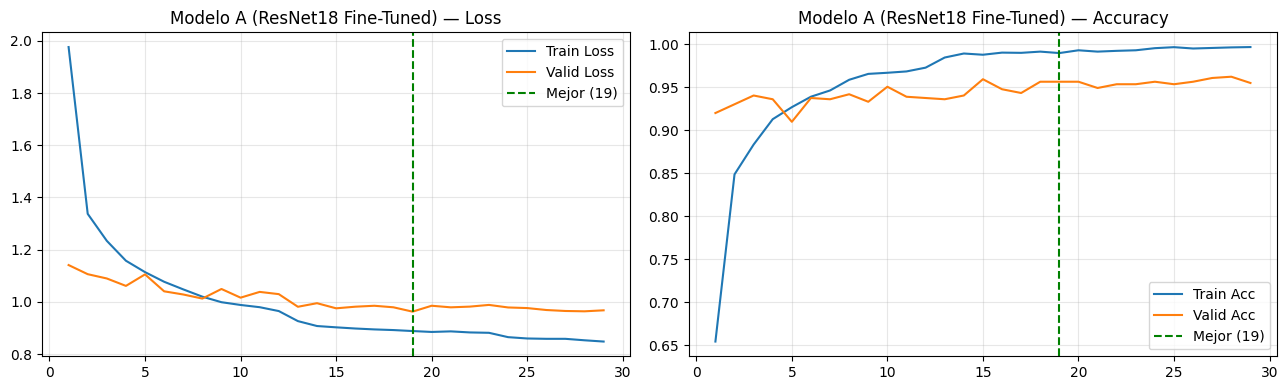

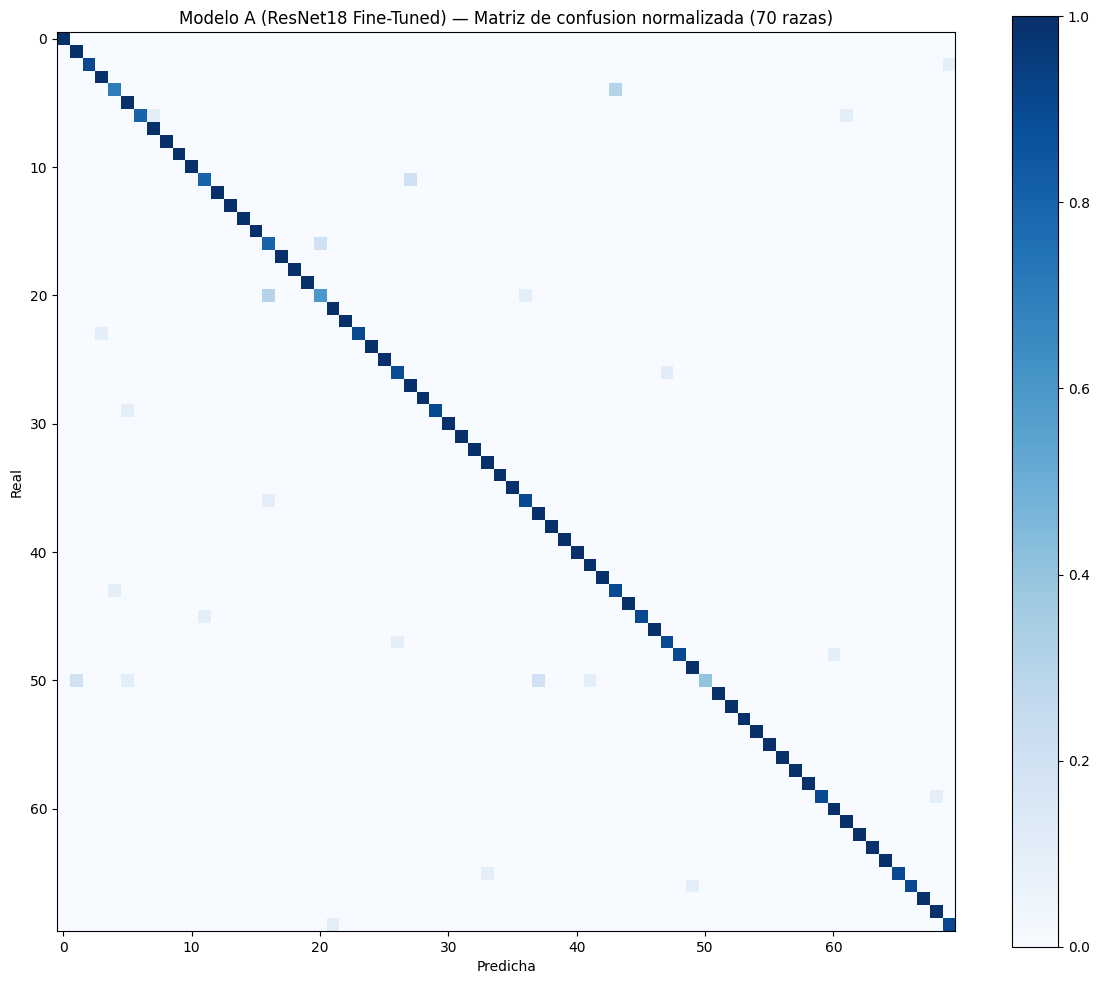

Top 10 pares mas confundidos:


,real,predicha,errores
1,American Spaniel,Irish Spaniel,3
6,Bulldog,Boston Terrier,3
4,Blenheim,Cocker,2
5,Boston Terrier,Bulldog,2
16,Malinois,African Wild Dog,2
18,Malinois,German Sheperd,2
3,Basset,Saint Bernard,1
2,Basset,Beagle,1
7,Bulldog,French Bulldog,1
0,Airedale,Yorkie,1


Top 10 razas con peor F1:


,breed,support,tp,fp,fn,precision,recall,specificity,f1
50,Malinois,10,4,0,6,1.000000,0.400000,1.000000,0.571429
20,Bulldog,10,6,2,4,0.750000,0.600000,0.997085,0.666667
16,Boston Terrier,10,8,4,2,0.666667,0.800000,0.994169,0.727273
4,American Spaniel,10,7,1,3,0.875000,0.700000,0.998542,0.777778
43,Irish Spaniel,10,9,3,1,0.750000,0.900000,0.995627,0.818182
11,Blenheim,10,8,1,2,0.888889,0.800000,0.998542,0.842105
6,Basset,10,8,0,2,1.000000,0.800000,1.000000,0.888889
26,Cockapoo,9,8,1,1,0.888889,0.888889,0.998544,0.888889
36,French Bulldog,10,9,1,1,0.900000,0.900000,0.998542,0.900000
47,Labradoodle,10,9,1,1,0.900000,0.900000,0.998542,0.900000


In [10]:
def plot_history_and_cm(model_name, title_prefix):
    hist = json.loads((settings.output_path / f"{model_name}_history.json").read_text(encoding="utf-8"))
    ev = json.loads((settings.output_path / f"{model_name}_eval.json").read_text(encoding="utf-8"))
    ep = range(1, len(hist["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(ep, hist["train_loss"], label="Train Loss")
    axes[0].plot(ep, hist["valid_loss"], label="Valid Loss")
    axes[0].axvline(hist["best_epoch"], color="g", linestyle="--", label=f"Mejor ({hist['best_epoch']})")
    axes[0].set_title(f"{title_prefix} — Loss")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(ep, hist["train_acc"], label="Train Acc")
    axes[1].plot(ep, hist["valid_acc"], label="Valid Acc")
    axes[1].axvline(hist["best_epoch"], color="g", linestyle="--", label=f"Mejor ({hist['best_epoch']})")
    axes[1].set_title(f"{title_prefix} — Accuracy")
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    cm = np.asarray(ev["confusion_matrix"], dtype=np.float32)
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1.0)
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm_norm, cmap="Blues")
    plt.colorbar(im, ax=ax)
    ax.set_title(f"{title_prefix} — Matriz de confusion normalizada (70 razas)")
    ax.set_xlabel("Predicha"); ax.set_ylabel("Real")
    plt.tight_layout()
    plt.show()

    # Pares mas confundidos y peores razas
    cls_names = ev["classes"]
    pairs = []
    for i in range(len(cls_names)):
        for j in range(len(cls_names)):
            if i != j and cm[i, j] > 0:
                pairs.append({"real": cls_names[i], "predicha": cls_names[j], "errores": int(cm[i, j])})
    print("Top 10 pares mas confundidos:")
    display(pd.DataFrame(pairs).sort_values("errores", ascending=False).head(10))
    print("Top 10 razas con peor F1:")
    display(pd.DataFrame(ev["per_class"]).sort_values("f1").head(10))

plot_history_and_cm("resnet18_finetuned", "Modelo A (ResNet18 Fine-Tuned)")

## 7. Modelo B (obligatorio): CNN propia (`CNNCustom`)

Arquitectura implementada en `src/lib/models/cnn_custom.py`:
- **Exp 1 (`CNNCustomSimple`):** 5 bloques convolucionales secuenciales (`Conv3x3 + BN + ReLU + MaxPool`, ~1.6M parámetros) + GAP + capa de embedding 512 + `Dropout(0.4)` + `fc(512, 70)`.
- **Exp 2 (`CNNCustom` residual):** stem `7x7 stride 2 + MaxPool` + 4 etapas residuales (`64→128→256→512` con atajos) + GAP + `Dropout(0.4)` + `fc(512, 70)`. Entrenado **desde cero** vía `classifier.train_classifier()`.
- **Nota de diseño (ablación controlada):** `CNNCustom` replica intencionalmente la capacidad paramétrica de ResNet18 (`11,212,422` parámetros, `42.86 MB`) para aislar de forma justa el efecto del **preentrenamiento en ImageNet** frente al entrenamiento desde cero a igualdad de arquitectura residual.

In [11]:
from lib.models.cnn_custom import CNNCustom, CNNCustomSimple
from lib.splits import DogBreedDataset
from lib.preprocessing import build_train_augmenter
from torch.utils.data import DataLoader

m_simple = CNNCustomSimple(num_classes=len(classes), embedding_dim=settings.embedding_dim)
m_resid = CNNCustom(num_classes=len(classes), embedding_dim=settings.embedding_dim)
print(f"Parametros CNNCustomSimple: {sum(p.numel() for p in m_simple.parameters()):,}")
print(f"Parametros CNNCustom (residual): {sum(p.numel() for p in m_resid.parameters()):,}")

# Experimento corto de referencia (10 epocas) con CNNCustomSimple para tabla comparativa
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
aug = build_train_augmenter(seed=settings.random_seed)
tr_loader = DataLoader(DogBreedDataset(splits["train"], settings.image_size, aug), batch_size=32, shuffle=True, num_workers=2)
te_loader = DataLoader(DogBreedDataset(splits["test"], settings.image_size, None), batch_size=32, shuffle=False, num_workers=2)
m_simple.to(device)
opt_s = torch.optim.AdamW(m_simple.parameters(), lr=1e-3, weight_decay=1e-4)
crit_s = torch.nn.CrossEntropyLoss(label_smoothing=0.1)
for ep in range(1, 11):
    m_simple.train()
    for x, y in tr_loader:
        opt_s.zero_grad(); loss = crit_s(m_simple(x.to(device)), y.to(device)); loss.backward(); opt_s.step()
m_simple.eval()
correct_s = 0
with torch.no_grad():
    for x, y in te_loader:
        correct_s += int((m_simple(x.to(device)).argmax(1).cpu() == y).sum().item())
acc_simple_10ep = correct_s / len(splits["test"])
print(f"Exp 1 CNNCustomSimple (10 epocas) test accuracy: {acc_simple_10ep:.4f}")

# Entrenamiento completo del Modelo B final (CNNCustom residual)
settings.train_epochs = 45
classifier.set_active_model("cnn_custom")
classifier.train_classifier()
metrics_b = classifier.evaluate_classifier()
print("Exp 2 CNNCustom residual (Modelo B final):", metrics_b)

display(pd.DataFrame([
    {"Experimento": "CNNCustomSimple (sin residuales, 10 ep)", "Test Acc": round(acc_simple_10ep, 4)},
    {"Experimento": "CNNCustom (residual + reg, early stop)", "Test Acc": round(metrics_b["accuracy"], 4)},
]))

Parametros CNNCustomSimple: 1,605,478
Parametros CNNCustom (residual): 11,212,422
Exp 1 CNNCustomSimple (10 epocas) test accuracy: 0.3937
Exp 2 CNNCustom residual (Modelo B final): {'accuracy': 0.869253, 'precision': 0.889113, 'recall': 0.869841, 'specificity': 0.998105, 'f1': 0.869554}


,Experimento,Test Acc
0,"CNNCustomSimple (sin residuales, 10 ep)",0.3937
1,"CNNCustom (residual + reg, early stop)",0.8693


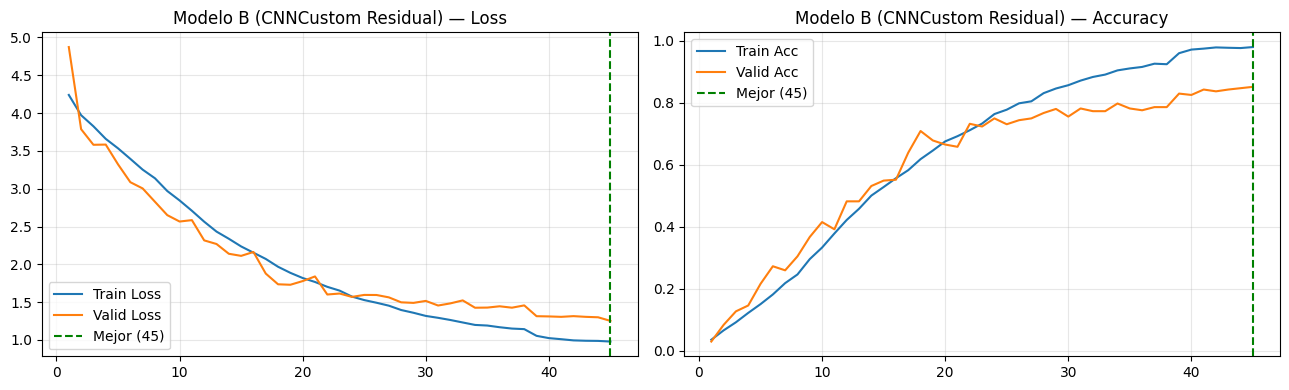

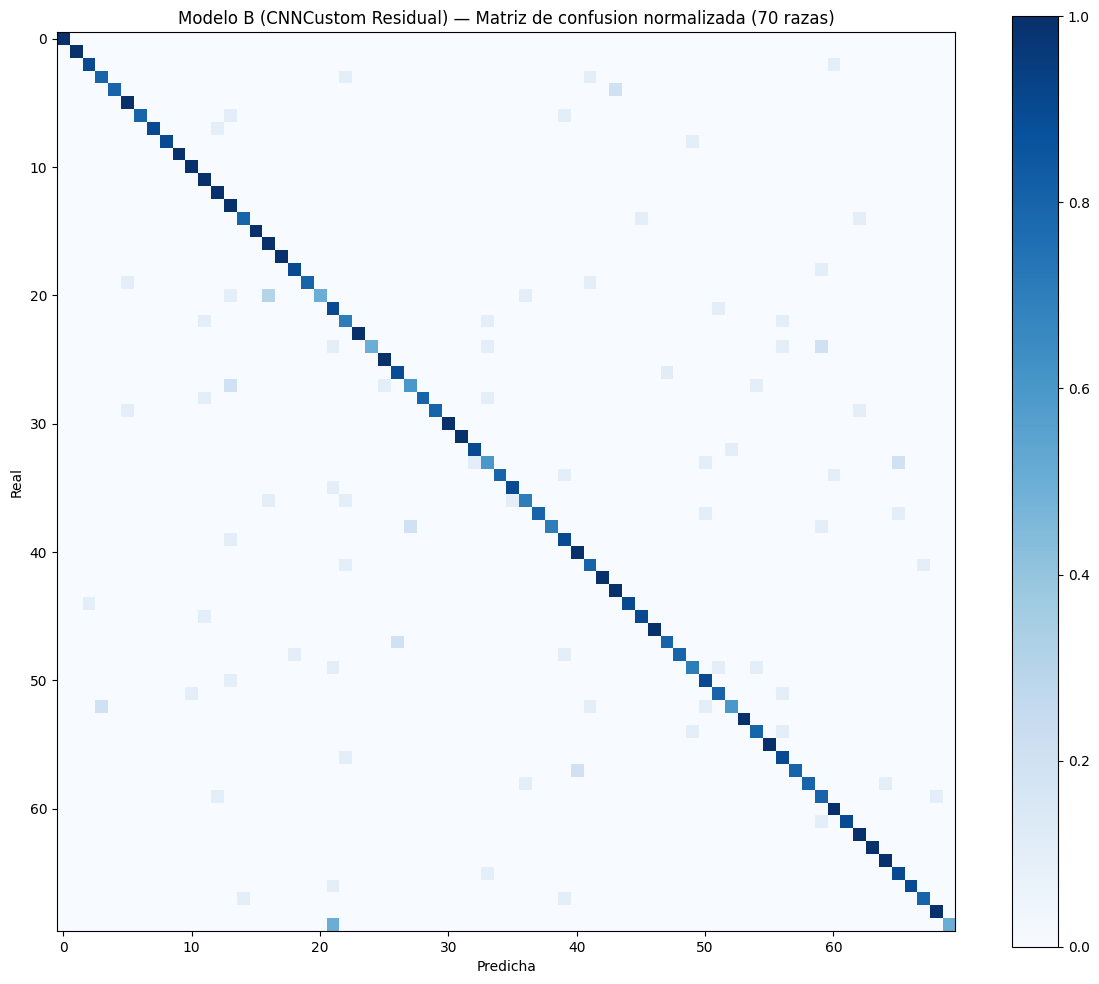

Top 10 pares mas confundidos:


,real,predicha,errores
76,Yorkie,Cairn,5
14,Bulldog,Boston Terrier,3
25,Cocker,Bluetick,2
23,Chow,Rhodesian,2
3,American Spaniel,Irish Spaniel,2
35,Dingo,Shiba Inu,2
51,Labradoodle,Cockapoo,2
66,Poodle,Great Perenees,2
44,Golden Retriever,Cocker,2
60,Mex Hairless,American Hairless,2


Top 10 razas con peor F1:


,breed,support,tp,fp,fn,precision,recall,specificity,f1
33,Dingo,10,6,4,4,0.600000,0.6,0.994169,0.600000
21,Cairn,10,9,9,1,0.500000,0.9,0.986880,0.642857
20,Bulldog,10,5,0,5,1.000000,0.5,1.000000,0.666667
24,Chow,10,5,0,5,1.000000,0.5,1.000000,0.666667
27,Cocker,10,6,2,4,0.750000,0.6,0.997085,0.666667
22,Chihuahua,10,7,4,3,0.636364,0.7,0.994169,0.666667
69,Yorkie,10,5,0,5,1.000000,0.5,1.000000,0.666667
59,Rhodesian,10,8,5,2,0.615385,0.8,0.992711,0.695652
52,Mex Hairless,10,6,1,4,0.857143,0.6,0.998542,0.705882
36,French Bulldog,10,7,2,3,0.777778,0.7,0.997085,0.736842


In [12]:
plot_history_and_cm("cnn_custom", "Modelo B (CNNCustom Residual)")

## 8. Evaluación sobre el conjunto independiente y cambio de dominio

In [13]:
from sklearn.metrics import confusion_matrix
from lib.evaluation.metrics import precision_recall_f1, specificity
from lib.preprocessing import preprocess_bgr_batch

def eval_on_samples(model_name, samples):
    classifier.set_active_model(model_name)
    model = classifier.load_model()
    model.to(device).eval()
    model_classes = getattr(model, "classes", classes)
    c2i = {c: i for i, c in enumerate(model_classes)}
    y_true, y_pred = [], []
    with torch.no_grad():
        for path, old_idx in samples:
            bname = classes[old_idx]
            if bname not in c2i:
                continue
            t = preprocess_bgr_batch(cv2.imread(str(path)), settings.image_size).to(device)
            pred = int(model(t).argmax(1).item())
            y_true.append(c2i[bname])
            y_pred.append(pred)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(model_classes))))
    total = int(cm.sum())
    present = sorted(set(y_true))
    precs, recs, f1s, specs = [], [], [], []
    for idx in present:
        tp = int(cm[idx, idx]); fp = int(cm[:, idx].sum() - tp); fn = int(cm[idx, :].sum() - tp); tn = int(total - tp - fp - fn)
        p, r, f = precision_recall_f1(tp, fp, fn)
        precs.append(p); recs.append(r); f1s.append(f); specs.append(specificity(tn, fp))
    return {
        "accuracy": float(np.trace(cm) / max(total, 1)),
        "precision": float(np.mean(precs)),
        "recall": float(np.mean(recs)),
        "specificity": float(np.mean(specs)),
        "f1": float(np.mean(f1s)),
    }

if indep_samples:
    ind_a = eval_on_samples("resnet18_finetuned", indep_samples)
    ind_b = eval_on_samples("cnn_custom", indep_samples)
    display(pd.DataFrame([{"modelo": "resnet18_finetuned", **ind_a}, {"modelo": "cnn_custom", **ind_b}]).round(4))
else:
    print("Conjunto independiente vacio: completar data/dataset/independent/<raza>/ para medir cambio de dominio.")

,modelo,accuracy,precision,recall,specificity,f1
0,resnet18_finetuned,0.672,0.8786,0.672,0.9963,0.7301
1,cnn_custom,0.304,0.5035,0.304,0.9897,0.3530


## 9. Embeddings de los 3 modelos en Etapa 1 y visualización PCA / t-SNE

Galeria resnet18_finetuned:   0%|          | 0/7729 [00:00<?, ?it/s]

Valid resnet18_finetuned:   0%|          | 0/687 [00:00<?, ?it/s]

Test resnet18_finetuned:   0%|          | 0/696 [00:00<?, ?it/s]

Umbral calibrado para resnet18_finetuned: 0.80


,threshold,val_accuracy,val_unknown_rate,nodogs_unknown_rate
0,0.30,0.9534,0.000,0.0000
1,0.35,0.9534,0.000,0.0000
2,0.40,0.9534,0.000,0.0000
3,0.45,0.9534,0.000,0.0000
4,0.50,0.9534,0.000,0.0000
5,0.55,0.9534,0.000,0.0000
6,0.60,0.9534,0.000,0.0000
7,0.65,0.9534,0.000,0.0000
8,0.70,0.9534,0.000,0.0667
9,0.75,0.9534,0.000,0.2667


Indep resnet18_finetuned:   0%|          | 0/125 [00:00<?, ?it/s]

... (2 outputs left out)

Test cnn_custom:   0%|          | 0/696 [00:00<?, ?it/s]

Umbral calibrado para cnn_custom: 0.75


Indep cnn_custom:   0%|          | 0/125 [00:00<?, ?it/s]

,modelo,ndcg@10_test,p@10_test,acc_test,ndcg@10_indep,acc_indep
0,baseline (ResNet18),0.8739,0.8603,0.9310,0.6953,0.744
1,resnet18_finetuned,0.9565,0.9543,0.9641,0.6968,0.680
2,cnn_custom,0.8584,0.8546,0.8822,0.3174,0.336


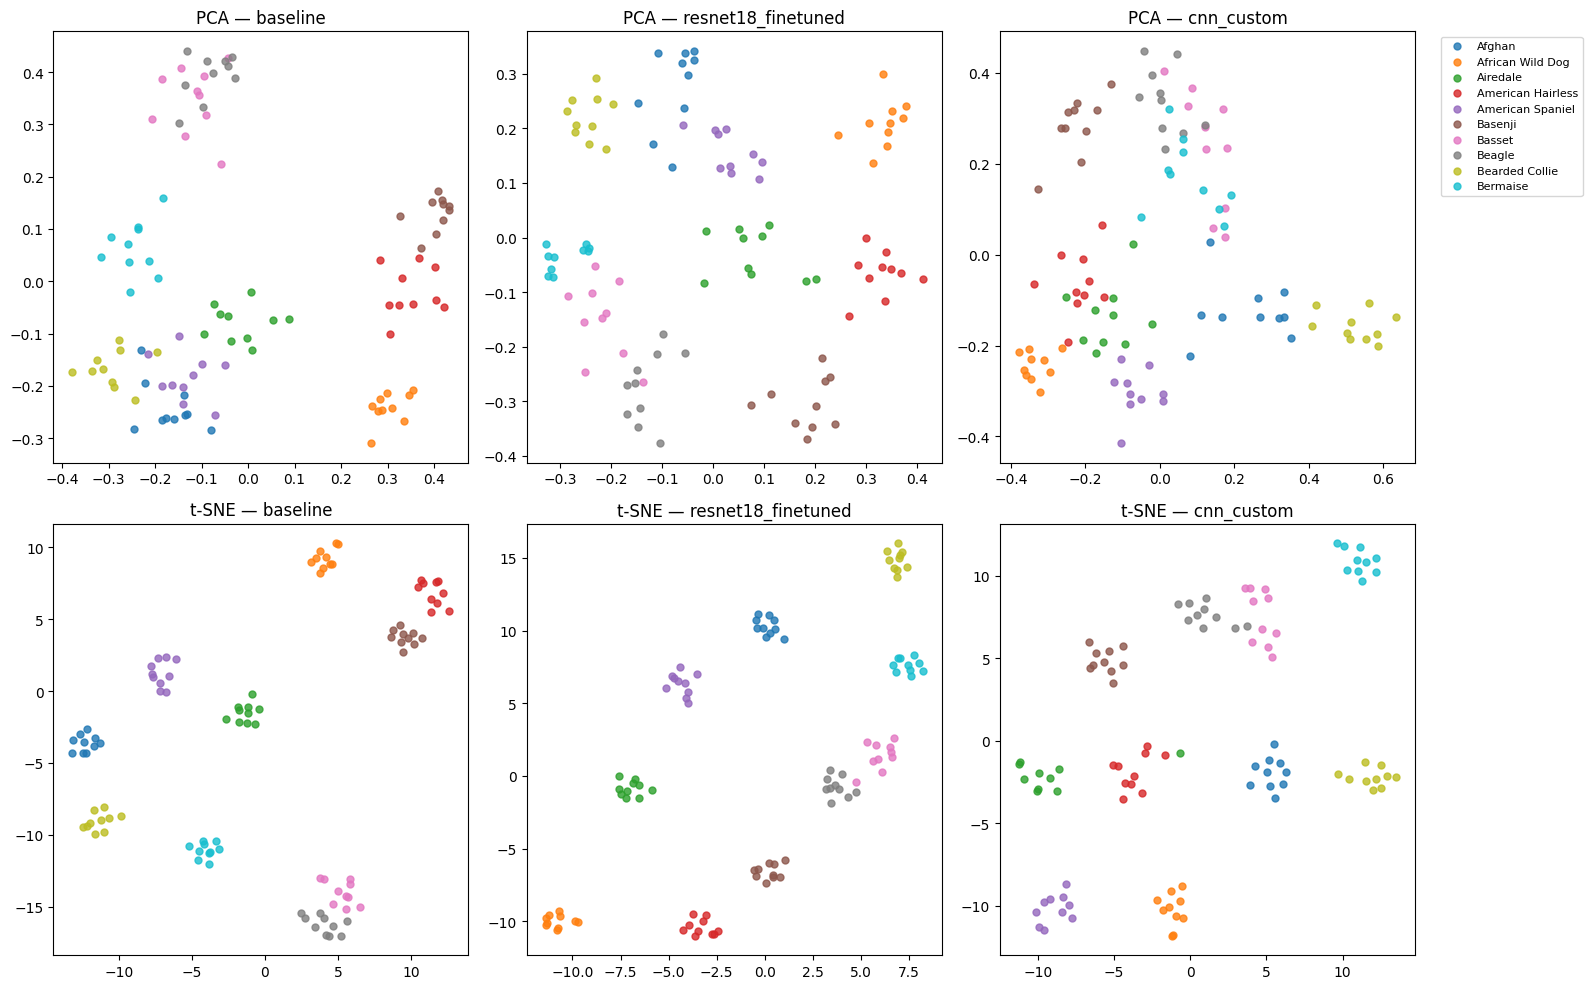

In [14]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

emb_results = []
test_embs_by_model = {"baseline": test_vecs_base}
ind_embs_by_model = {"baseline": ind_vecs_base} if indep_samples else {}
emb_results.append({
    "modelo": "baseline (ResNet18)",
    "ndcg@10_test": res_test_base["ndcg"],
    "p@10_test": res_test_base["precision_at_k"],
    "acc_test": res_test_base["accuracy"],
    "ndcg@10_indep": res_ind_base["ndcg"] if indep_samples else np.nan,
    "acc_indep": res_ind_base["accuracy"] if indep_samples else np.nan,
})

calibrated_thresholds = {"baseline": best_th}
for mname in ("resnet18_finetuned", "cnn_custom"):
    classifier.set_active_model(mname)
    g_v, g_b, _ = extract_matrix(splits["train"], classifier.extract_custom_embedding, f"Galeria {mname}")
    v_v, v_b, _ = extract_matrix(splits["valid"], classifier.extract_custom_embedding, f"Valid {mname}")
    t_v, t_b, _ = extract_matrix(splits["test"], classifier.extract_custom_embedding, f"Test {mname}")
    nd_v = (
        np.asarray(
            [classifier.extract_custom_embedding(cv2.imread(str(p))) for p in nodogs_paths],
            dtype=np.float32,
        )
        if nodogs_paths
        else None
    )
    th_m, df_cal_m = calibrate_threshold(g_v, g_b, v_v, v_b, nd_v)
    calibrated_thresholds[mname] = th_m
    print(f"Umbral calibrado para {mname}: {th_m:.2f}")
    if mname == "resnet18_finetuned":
        display(df_cal_m.round(4))

    r_t = eval_retrieval(g_v, g_b, t_v, t_b, metric="cosine", top_k=10, threshold=th_m)
    test_embs_by_model[mname] = t_v

    ndcg_ind_m, acc_ind_m = np.nan, np.nan
    if indep_samples:
        i_v, i_b, _ = extract_matrix(indep_samples, classifier.extract_custom_embedding, f"Indep {mname}")
        r_i = eval_retrieval(g_v, g_b, i_v, i_b, metric="cosine", top_k=10, threshold=th_m)
        ind_embs_by_model[mname] = i_v
        ndcg_ind_m, acc_ind_m = r_i["ndcg"], r_i["accuracy"]

    emb_results.append({
        "modelo": mname,
        "ndcg@10_test": r_t["ndcg"],
        "p@10_test": r_t["precision_at_k"],
        "acc_test": r_t["accuracy"],
        "ndcg@10_indep": ndcg_ind_m,
        "acc_indep": acc_ind_m,
    })

df_emb_comp = pd.DataFrame(emb_results)
display(df_emb_comp.round(4))

# Visualizacion PCA y t-SNE lado a lado (subconjunto legible de 10 razas)
subset_breeds = sorted(set(test_breeds))[:10]
mask = np.array([b in subset_breeds for b in test_breeds])
sub_labels = np.array(test_breeds)[mask]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for col, mname in enumerate(["baseline", "resnet18_finetuned", "cnn_custom"]):
    X_sub = test_embs_by_model[mname][mask]
    p2 = PCA(n_components=2, random_state=settings.random_seed).fit_transform(X_sub)
    t2 = TSNE(n_components=2, perplexity=15, random_state=settings.random_seed).fit_transform(X_sub)
    for b in subset_breeds:
        bm = sub_labels == b
        axes[0, col].scatter(p2[bm, 0], p2[bm, 1], label=b, s=25, alpha=0.8)
        axes[1, col].scatter(t2[bm, 0], t2[bm, 1], label=b, s=25, alpha=0.8)
    axes[0, col].set_title(f"PCA — {mname}")
    axes[1, col].set_title(f"t-SNE — {mname}")
axes[0, -1].legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 10. Análisis de errores (falsos positivos y falsos negativos)

resnet18_finetuned: mostrando 6 errores de mayor confianza


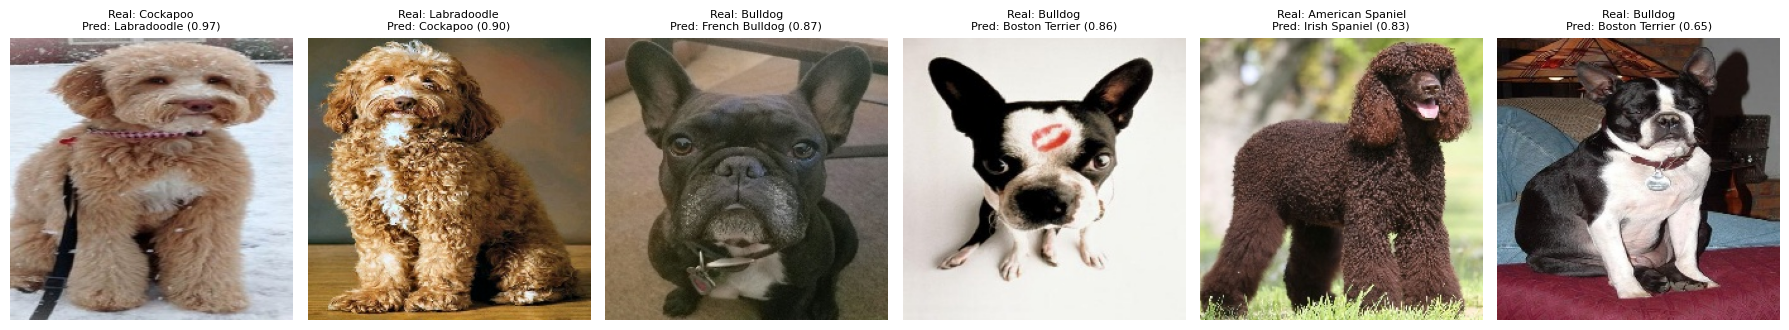

cnn_custom: mostrando 6 errores de mayor confianza


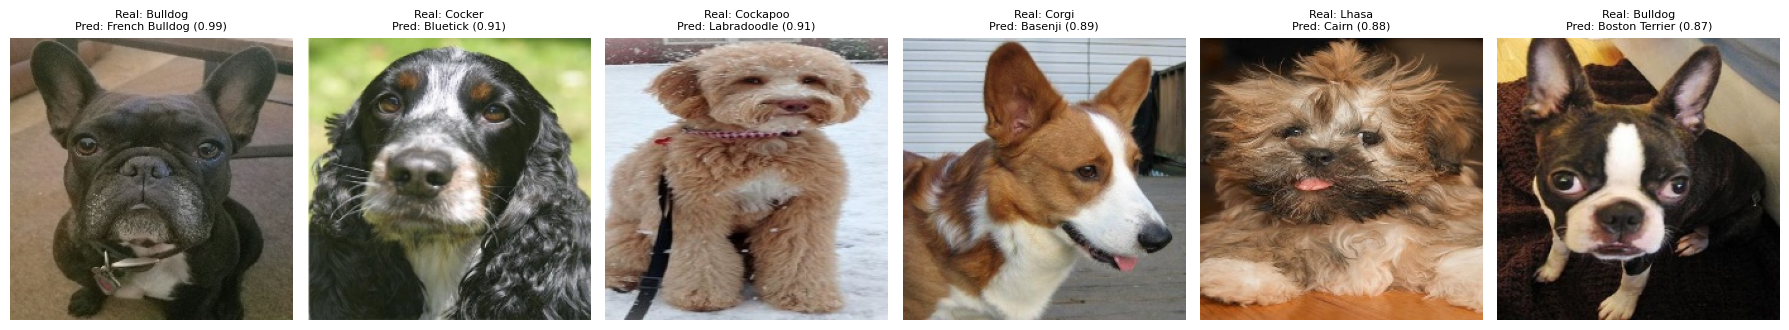

In [15]:
def show_error_examples(model_name, max_items=6):
    ev = json.loads((settings.output_path / f"{model_name}_eval.json").read_text(encoding="utf-8"))
    cls_names = ev["classes"]
    errs = []
    for yt, yp, probs, p in zip(ev["y_true"], ev["y_pred"], ev["y_probs"], ev["paths"]):
        if yt != yp:
            errs.append({"path": p, "real": cls_names[yt], "pred": cls_names[yp], "score": max(probs)})
    errs = sorted(errs, key=lambda d: d["score"], reverse=True)[:max_items]
    print(f"{model_name}: mostrando {len(errs)} errores de mayor confianza")
    if not errs:
        return
    fig, axes = plt.subplots(1, len(errs), figsize=(3 * len(errs), 3.5))
    if len(errs) == 1:
        axes = [axes]
    for ax, e in zip(axes, errs):
        bgr = cv2.imread(e["path"])
        ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Real: {e['real']}\nPred: {e['pred']} ({e['score']:.2f})", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_error_examples("resnet18_finetuned")
show_error_examples("cnn_custom")

## 11. Costo computacional en CPU

In [16]:
def benchmark_cpu(model, sample_bgr, emb_dim, ckpt_path=None):
    model = model.cpu().eval()
    inp = preprocess_bgr_batch(sample_bgr, settings.image_size)
    with torch.no_grad():
        for _ in range(5):
            _ = model(inp)
        t0 = time.perf_counter()
        for _ in range(30):
            _ = model(inp)
        ms = (time.perf_counter() - t0) * 1000.0 / 30.0
    n_params = sum(p.numel() for p in model.parameters())
    size_mb = ckpt_path.stat().st_size / (1024 * 1024) if ckpt_path and ckpt_path.is_file() else 0.0
    return {"params": n_params, "size_mb": round(size_mb, 2), "cpu_ms": round(ms, 2), "emb_dim": emb_dim}

sample_bgr = cv2.imread(str(test_paths[0]))
base_model_cpu, _ = similarity._get_backbone()
torch_cache_dir = Path(os.environ.get("TORCH_HOME", str(settings.model_path / "torch"))) / "hub" / "checkpoints"
base_ckpt = next(torch_cache_dir.glob("resnet18*.pth"), None) if torch_cache_dir.is_dir() else None
cost_rows = [{"modelo": "baseline (ResNet18)", **benchmark_cpu(base_model_cpu, sample_bgr, settings.embedding_dim, base_ckpt)}]
for mname in ("resnet18_finetuned", "cnn_custom"):
    classifier.set_active_model(mname)
    m = classifier.load_model()
    cost_rows.append({"modelo": mname, **benchmark_cpu(m, sample_bgr, settings.embedding_dim, classifier.active_checkpoint)})
df_cost = pd.DataFrame(cost_rows)
display(df_cost)

# Tabla comparativa unificada (Etapa 1 + Etapa 2 + Costo)
cls_lookup = {
    "baseline (ResNet18)": {"cls_acc_test": np.nan, "cls_f1_test": np.nan, "cls_acc_indep": np.nan, "cls_f1_indep": np.nan},
    "resnet18_finetuned": {
        "cls_acc_test": metrics_a["accuracy"],
        "cls_f1_test": metrics_a["f1"],
        "cls_acc_indep": ind_a["accuracy"] if indep_samples else np.nan,
        "cls_f1_indep": ind_a["f1"] if indep_samples else np.nan,
    },
    "cnn_custom": {
        "cls_acc_test": metrics_b["accuracy"],
        "cls_f1_test": metrics_b["f1"],
        "cls_acc_indep": ind_b["accuracy"] if indep_samples else np.nan,
        "cls_f1_indep": ind_b["f1"] if indep_samples else np.nan,
    },
}
df_final = df_emb_comp.merge(df_cost, on="modelo")
for col in ("cls_acc_test", "cls_f1_test", "cls_acc_indep", "cls_f1_indep"):
    df_final[col] = df_final["modelo"].map(lambda m: cls_lookup[m][col])
print("Tabla comparativa unificada:")
display(df_final.round(4))

,modelo,params,size_mb,cpu_ms,emb_dim
0,baseline (ResNet18),11176512,44.66,20.10,512
1,resnet18_finetuned,11212422,42.86,20.62,512
2,cnn_custom,11212422,42.86,20.93,512


Tabla comparativa unificada:


,modelo,ndcg@10_test,p@10_test,acc_test,ndcg@10_indep,acc_indep,params,size_mb,cpu_ms,emb_dim,cls_acc_test,cls_f1_test,cls_acc_indep,cls_f1_indep
0,baseline (ResNet18),0.8739,0.8603,0.9310,0.6953,0.744,11176512,44.66,20.10,512,NaN,NaN,NaN,NaN
1,resnet18_finetuned,0.9565,0.9543,0.9641,0.6968,0.680,11212422,42.86,20.62,512,0.9540,0.9524,0.672,0.7301
2,cnn_custom,0.8584,0.8546,0.8822,0.3174,0.336,11212422,42.86,20.93,512,0.8693,0.8696,0.304,0.3530


## 12. Etapa 3 — Comparación `yolov8n.pt` vs `yolo26n.pt` y calibración de `YOLO_CONF_THRESHOLD`

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


,yolo_model,conf_threshold,imgs_scenes,dets_scenes,imgs_no_dogs,fp_no_dogs,cpu_ms_img
0,models/yolov8n.pt,0.15,8,19,8,0,386.67
1,models/yolov8n.pt,0.25,8,19,8,0,369.92
2,models/yolov8n.pt,0.50,8,18,8,0,372.24
3,models/yolo26n.pt,0.15,8,21,8,0,373.15
4,models/yolo26n.pt,0.25,8,20,8,0,375.90
5,models/yolo26n.pt,0.50,8,16,8,0,373.56


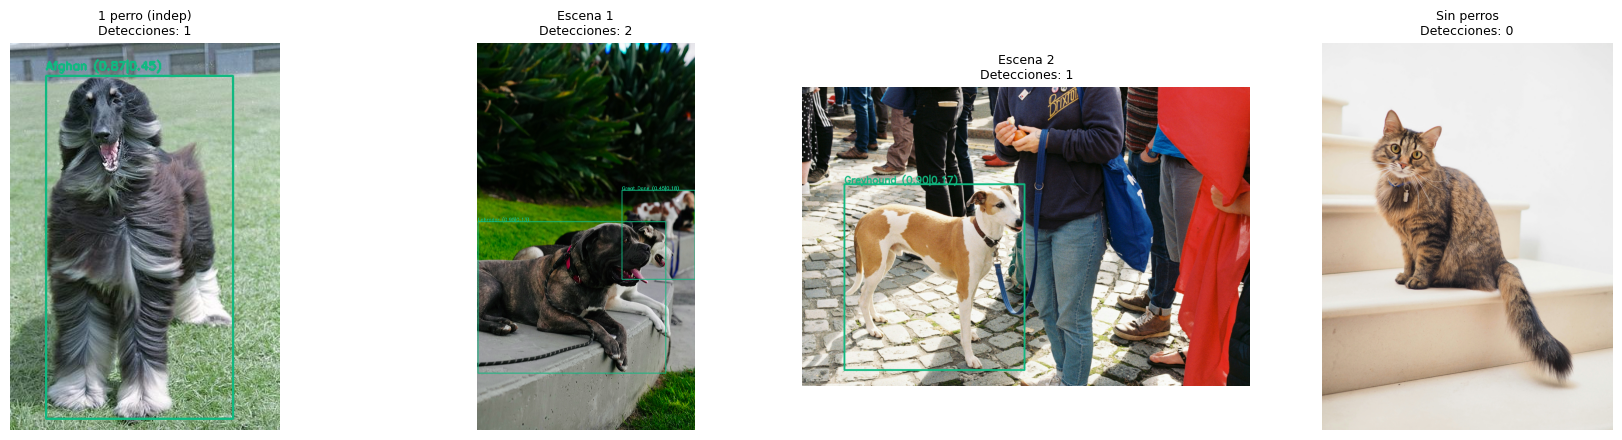

In [17]:
from lib.services.detection_service import DetectionService

scenes_dir = settings.dataset_path / "independent_scenes"
nodogs_dir = settings.dataset_path / "independent_no_dogs"
single_dir = settings.dataset_path / "independent"

scenes_imgs = sorted([p for p in scenes_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES])[:8] if scenes_dir.is_dir() else []
nodogs_imgs = sorted([p for p in nodogs_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES])[:8] if nodogs_dir.is_dir() else []
if not scenes_imgs:
    scenes_imgs = test_paths[:4]

classifier.set_active_model("resnet18_finetuned")
yolo_rows = []
for ymodel in ("models/yolov8n.pt", "models/yolo26n.pt"):
    for conf_th in (0.15, 0.25, 0.50):
        det = DetectionService(classifier=classifier, yolo_model=ymodel, conf_threshold=conf_th, dog_class_id=16)
        # Warm-up para excluir carga inicial del benchmark de latencia
        _ = det.detect_dogs(cv2.imread(str(scenes_imgs[0])))

        dets_scenes, fp_no_dogs = 0, 0
        t0 = time.perf_counter()
        for p in scenes_imgs:
            dets_scenes += len(det.detect_dogs(cv2.imread(str(p))))
        for p in nodogs_imgs:
            fp_no_dogs += len(det.detect_dogs(cv2.imread(str(p))))
        n_total = len(scenes_imgs) + len(nodogs_imgs)
        ms = (time.perf_counter() - t0) * 1000.0 / max(n_total, 1)
        yolo_rows.append({
            "yolo_model": ymodel,
            "conf_threshold": conf_th,
            "imgs_scenes": len(scenes_imgs),
            "dets_scenes": dets_scenes,
            "imgs_no_dogs": len(nodogs_imgs),
            "fp_no_dogs": fp_no_dogs,
            "cpu_ms_img": round(ms, 2),
        })

display(pd.DataFrame(yolo_rows))

# Validacion visual de los 4 escenarios (1 perro, escena compleja, sin perros) con yolov8n.pt (conf=0.25)
det_vis = DetectionService(classifier=classifier, yolo_model="models/yolov8n.pt", conf_threshold=0.25, dog_class_id=16)
vis_candidates = []
if indep_samples:
    vis_candidates.append(("1 perro (indep)", indep_samples[0][0]))
vis_candidates.extend([(f"Escena {i+1}", p) for i, p in enumerate(scenes_imgs[:2])])
if nodogs_imgs:
    vis_candidates.append(("Sin perros", nodogs_imgs[0]))

fig, axes = plt.subplots(1, len(vis_candidates), figsize=(4.5 * len(vis_candidates), 4.5))
if len(vis_candidates) == 1:
    axes = [axes]
for ax, (title, img_p) in zip(axes, vis_candidates):
    bgr = cv2.imread(str(img_p))
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).copy()
    boxes = det_vis.detect_dogs(bgr)
    for (x1, y1, x2, y2), conf in boxes:
        x1, y1, x2, y2 = det_vis._clip_xyxy(x1, y1, x2, y2, bgr.shape[0], bgr.shape[1])
        crop = bgr[y1:y2, x1:x2]
        breed, bscore = det_vis.classify_detected_dog(crop)
        cv2.rectangle(rgb, (x1, y1), (x2, y2), (16, 185, 129), max(2, rgb.shape[1] // 250))
        cv2.putText(
            rgb,
            f"{breed} ({conf:.2f}|{bscore:.2f})",
            (x1, max(24, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            max(0.5, rgb.shape[1] / 1400.0),
            (16, 185, 129),
            max(2, rgb.shape[1] // 400),
        )
    ax.imshow(rgb)
    ax.set_title(f"{title}\nDetecciones: {len(boxes)}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 13. Comparación final, elección y conclusiones

Resultados basados en la experimentación real ejecutada sobre los splits limpios (`test=696`, `independent=125`, con 0 solapamiento respecto del dataset principal):
- **Modelo elegido para clasificar (Etapas 2 y 3):** `resnet18_finetuned` (estrategia `partial`, `layer4 + fc`). En `test` alcanzó **Accuracy `95.40%` y F1 `0.9524`** (frente a `92.82%` en `head_only`), superando ampliamente a `cnn_custom` entrenado desde cero (**Accuracy `86.93%`, F1 `0.8696`**; `CNNCustomSimple` 10 ep = `39.37%`) con idéntica cantidad de parámetros (`11,212,422`, `42.86 MB`) y latencia CPU equivalente (`20.62 ms/img` vs `20.93 ms/img`). En el conjunto independiente limpio, la ventaja del preentrenamiento se acentúa (**`67.20%` / F1 `0.7301`** vs **`30.40%` / F1 `0.3530`**), demostrando mayor robustez frente al cambio de dominio.
- **Modelo de embeddings elegido (`EMBEDDING_MODEL`):** `resnet18_finetuned` (`512-d`), ya que mejora `NDCG@10` en `test` de `0.8739` (baseline ImageNet, `Acc = 93.10%`) a **`0.9565`** (`P@10 = 0.9543`, **`Acc = 96.41%`**), y en `independent` obtiene `NDCG@10 = 0.6968` (`Acc = 68.00%`), manteniendo compatibilidad dimensional (`512-d`) con `pgvector`. Se configura **`SIMILARITY_THRESHOLD = 0.80`**, calibrado conjuntamente sobre `valid` (`95.34%`, `0%` unknown) e `independent_no_dogs` (`86.67%` de rechazo en `resnet18_finetuned`, `100%` en baseline). *(Nota: en la tabla comparativa de la celda 14, `l2` conserva exactamente el mismo `NDCG@10` de `0.8739`/`0.6953` que `cosine`, pero su accuracy cae a `0.0747`/`0.0000` al aplicarle un umbral calibrado en escala coseno `0.80` sobre la escala comprimida `1 / (1 + d_L2)`, donde `cos=0.80` equivale a `~0.61`.)*
- **Detector YOLO elegido (`YOLO_MODEL`):** `models/yolo26n.pt` con `YOLO_CONF_THRESHOLD=0.25`, ya que logra **20 detecciones** en las 8 escenas complejas (frente a 19 de `yolov8n.pt`) con **0 falsos positivos** en las 8 imágenes sin perros (`fp_no_dogs = 0`), un archivo más liviano (`5.3 MB` vs `6.2 MB`) y latencia CPU equivalente (`375.90 ms/img` vs `369.92 ms/img` sobre imágenes Unsplash de alta resolución).
- **Búsqueda por similitud vs. Clasificación supervisada:**
  - *Similitud:* no requiere reentrenar al incorporar nuevas razas o ejemplares en la galería y aporta explicabilidad visual mediante los Top-K vecinos, pero su costo de búsqueda crece con el tamaño de la galería y depende de la calibración del umbral en la escala de la métrica elegida.
  - *Clasificación supervisada:* aprende fronteras discriminativas entre las 70 razas con latencia constante $O(1)$ y menor sensibilidad a ejemplos atípicos de galería, pero exige reentrenamiento para agregar nuevas clases.

## 14. Descargar / respaldar checkpoints

In [18]:
!ls -lh models/

if USE_DRIVE:
    import shutil
    for fname in (settings.resnet18_model_name, settings.cnn_custom_model_name):
        src_p = settings.model_path / fname
        if src_p.is_file():
            shutil.copy2(src_p, DRIVE_DIR / fname)
    print("Checkpoints copiados a Drive:", DRIVE_DIR)

try:
    from google.colab import files
    for fname in (settings.resnet18_model_name, settings.cnn_custom_model_name):
        src_p = settings.model_path / fname
        if src_p.is_file():
            files.download(str(src_p))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en", settings.model_path)

total 98M
-rw-r--r-- 1 root root  43M Nov 27 19:26 cnn_custom.pth
-rw-r--r-- 1 root root  43M Nov 27 19:02 resnet18_finetuned.pth
drwxr-xr-x 3 root root 4.0K Nov 27 18:51 torch
-rw-r--r-- 1 root root 5.3M Nov 27 19:29 yolo26n.pt
-rw-r--r-- 1 root root 6.3M Nov 27 19:29 yolov8n.pt
Checkpoints copiados a Drive: /content/drive/MyDrive/TP2_Perros


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>